# Data Structures & Algorithms: Backtracking

> **Who is this for:** a beginner who can write recursive Python functions, and a university student preparing for exams or coding interviews (subsets, permutations, N-Queens and Sudoku are interview classics).
>
> **What you will learn:**
> - the backtracking template **choose → explore → un-choose**, and the **state-space tree** it walks
> - **pruning**: cutting off branches that cannot lead to a solution, and how much work it saves (measured)
> - the classic problems: subsets, permutations (with and without duplicates), combinations and combination sum, N-Queens (counting solutions for n = 1..10), Sudoku, rat in a maze, word search, graph m-colouring, Hamiltonian paths, balanced parentheses, palindrome partitioning
> - when to use backtracking vs. dynamic programming vs. brute force
> - how backtracking becomes **constraint satisfaction** in AI
>
> **Prerequisites:** [`01_Python/01_basic.ipynb`](../../01_Python/01_basic.ipynb), recursion from [`01_complexity_analysis_and_recursion.ipynb`](01_complexity_analysis_and_recursion.ipynb), and ideally [`09_dynamic_programming.ipynb`](09_dynamic_programming.ipynb).
>
> **Time needed:** about 2-3 hours.
>
> **Runs on:** CPU, no API key, no internet. Executes in well under a minute.
>
> **Optional track:** this notebook is part of the university-level fundamentals track; recommended for BS/MS AI students and interview prep.

## Explained simply

**Backtracking** is a careful way to try every possibility without wasting time on hopeless ones. Picture walking through a maze: at each junction you pick a path, and when you hit a dead end you walk back to the last junction and try the next path. The computer does the same with choices: make one choice, keep going, and if things break, undo that choice and try another. The clever part is **pruning**: as soon as a half-built answer already breaks a rule, you stop, so you never explore the many dead ends behind it. A Sudoku player does exactly this, writing a digit in pencil and rubbing it out the moment it clashes with its row, column or box. Backtracking solves puzzles, timetables and seating plans, and it is the engine inside AI constraint solvers and game-playing programs.

**Tiny example.** Put 4 queens on a 4 × 4 chessboard so that no queen can attack another. Put the first queen in row 1, column 2; in row 2 the only safe square is then column 4; in row 3 only column 1; in row 4 only column 3. Done: one solution is columns (2, 4, 1, 3). Whenever a row has no safe square, you undo the last queen and move it. There are 4 × 4 × 4 × 4 = 256 ways to put one queen in each row, but the pruned search checks only 17 partial boards and still finds both of the 2 solutions.

| Concept | Simple meaning | Where you see it in real life / AI |
|---|---|---|
| Backtracking | try a choice, go deeper, undo it if it leads nowhere | solving Sudoku and mazes; AI constraint solvers and SAT solvers |
| Pruning | stop as soon as a half-built answer breaks a rule | rubbing out a clashing Sudoku digit at once; alpha-beta pruning in chess engines |
| State-space tree | the tree of all possible choices, one level per decision | game trees in chess programs; Tree-of-Thoughts reasoning in LLMs |

## Table of contents

1. What is backtracking? The template and the state-space tree
2. Pruning
3. Subsets
4. Permutations (with and without duplicates)
5. Combinations and combination sum
6. N-Queens
7. Sudoku
8. Grids: rat in a maze and word search
9. Graph m-colouring
10. Hamiltonian paths
11. Generating balanced parentheses
12. Palindrome partitioning
13. Measuring how much pruning saves
14. Backtracking vs. DP vs. brute force
15. How this connects to AI: constraint satisfaction and beyond
16. Recap, practice problems, further reading

In [1]:
import itertools                  # brute-force checkers
import math
import random
import time

import matplotlib.pyplot as plt
import networkx as nx
import pandas as pd

random.seed(3)
print("Ready.")

Ready.


## 1. What is backtracking?

> 💡 **In plain English:** backtracking builds an answer one choice at a time and undoes the last choice whenever it hits a dead end, like walking back in a maze.

**Analogy.** You are in a maze. At every junction you pick a corridor. If you hit a dead end, you **walk back to the last junction** and try the next corridor you have not tried. You never explore the same corridor twice from the same junction, and you stop exploring a corridor the moment you see it is a dead end.

**Backtracking** is a systematic way to search **all candidate solutions** that are built one choice at a time. It extends a **partial solution** step by step; as soon as the partial solution **cannot** be completed into a valid solution, it abandons it and undoes the last choice ("backtracks").

### The template: choose → explore → un-choose

```
def backtrack(state):
    if state is a complete solution:
        record(state)
        return
    for choice in candidates(state):
        if is_valid(state, choice):      # pruning: skip choices that already break a constraint
            make(choice)                 # 1. CHOOSE   (modify the state)
            backtrack(state)             # 2. EXPLORE  (recurse deeper)
            undo(choice)                 # 3. UN-CHOOSE (restore the state exactly)
```

The **un-choose** step is what makes it *back*-tracking: one shared state object is modified and restored, so memory stays O(depth) instead of copying the state at every step.

### The state-space tree

Every run of a backtracking algorithm walks an (implicit) tree:

- the **root** is the empty partial solution;
- each **edge** is one choice;
- each **node** is a partial solution; **leaves** are complete candidates or dead ends.

Backtracking is a **depth-first search** of this tree. Below we draw the state-space tree for "all subsets of {1, 2, 3}": at depth `i` we decide whether element `i+1` is in (+) or out (−).

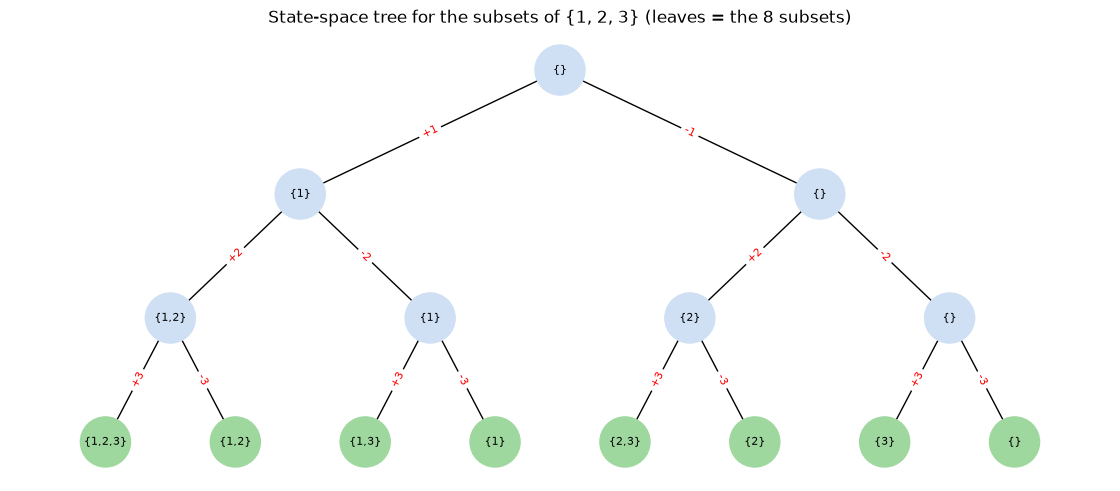

nodes in the tree: 15 | leaves: 8


In [2]:
def subset_tree(items):
    # Build the include/exclude state-space tree as a networkx graph with a top-down layout
    G, pos, labels, edge_labels = nx.DiGraph(), {}, {}, {}
    next_leaf = itertools.count()
    def build(i, current):
        node = len(labels)
        labels[node] = "{" + ",".join(map(str, current)) + "}"
        G.add_node(node)
        kids = []
        if i < len(items):
            for take in (True, False):
                child = build(i + 1, current + [items[i]] if take else current)
                G.add_edge(node, child)
                edge_labels[(node, child)] = ("+" if take else "-") + str(items[i])
                kids.append(child)
        pos[node] = (next(next_leaf), -i) if not kids else ((pos[kids[0]][0] + pos[kids[-1]][0]) / 2, -i)
        return node
    build(0, [])
    return G, pos, labels, edge_labels


G, pos, labels, edge_labels = subset_tree([1, 2, 3])
leaves = [v for v in G if G.out_degree(v) == 0]
plt.figure(figsize=(11, 4.5))
nx.draw(G, pos, labels=labels, node_size=1300, font_size=8, arrows=False,
        node_color=["#9fd89f" if v in leaves else "#cfe0f5" for v in G])
nx.draw_networkx_edge_labels(G, pos, edge_labels=edge_labels, font_color="red", font_size=8)
plt.title("State-space tree for the subsets of {1, 2, 3} (leaves = the 8 subsets)")
plt.show()
print("nodes in the tree:", G.number_of_nodes(), "| leaves:", len(leaves))

**What just happened?** The tree has 15 nodes: 1 root, 2 + 4 partial decisions, and 8 leaves, one per subset (2³ = 8). Backtracking visits these nodes in depth-first order: `{}` → `{1}` → `{1,2}` → `{1,2,3}`, back up, `{1,2}`, back up, `{1}` → `{1,3}`, and so on.

## 2. Pruning

> 💡 **In plain English:** pruning means giving up on a half-built answer as soon as it breaks a rule, which skips everything that would have grown from it.

**Pruning** means not expanding a node whose partial solution can already be shown to be useless. The whole subtree below it is skipped, which can turn an impossible search into a fast one.

| Kind of pruning | Rule | Example |
|---|---|---|
| **Feasibility (constraint) pruning** | the partial solution already violates a constraint | two queens attack each other; a digit repeats in a Sudoku row |
| **Bound pruning** (branch and bound) | even the best completion cannot beat the best solution found so far | in a min-cost search, the cost so far already exceeds the best complete cost |
| **Symmetry / duplicate pruning** | the branch would only produce a solution already produced | permutations of a list with repeated values |
| **Ordering heuristics** | not pruning, but choose the most constrained variable first so failures appear early | Sudoku: fill the cell with the fewest candidates first (MRV) |

The worst case of backtracking is still exponential (it is often used for NP-hard problems), but good pruning shrinks the tree by orders of magnitude, as section 13 measures.

> 🎓 **Exam / interview tip:** describe a backtracking solution by naming (1) the **state**, (2) the **choices** at each step, (3) the **constraint** checked for pruning, and (4) the **goal test**. Then give the size of the state-space tree as the worst-case bound (e.g. `2ⁿ` subsets, `n!` permutations).

## 3. Subsets (the power set)

> 💡 **In plain English:** list every group you can pick from a set of items by deciding "in or out" for each item.

All `2ⁿ` subsets of `n` distinct items. Two equivalent backtracking styles:

1. **Include/exclude** (the binary tree above): at depth `i`, branch on "take item `i`" or "skip item `i`".
2. **Loop from a start index**: every node is a subset; its children add one later item. This style generalises to combinations.

Worked example (style 2) for `[1, 2, 3]`: `[] → [1] → [1,2] → [1,2,3]`, back, `[1,3]`, back, back, `[2] → [2,3]`, back, `[3]`: 8 subsets.

In [3]:
def subsets_include_exclude(items):
    out, current = [], []
    def bt(i):
        if i == len(items):                   # leaf: a complete decision for every item
            out.append(current.copy())        # copy! current keeps changing
            return
        current.append(items[i])              # choose: include items[i]
        bt(i + 1)                             # explore
        current.pop()                         # un-choose
        bt(i + 1)                             # explore the "exclude" branch
    bt(0)
    return out


def subsets_loop(items):
    out, current = [], []
    def bt(start):
        out.append(current.copy())            # every node is a valid subset
        for i in range(start, len(items)):
            current.append(items[i])          # choose
            bt(i + 1)                         # explore (only later items: avoids duplicates)
            current.pop()                     # un-choose
    bt(0)
    return out


print(subsets_loop([1, 2, 3]))
for n in range(0, 9):
    items = list(range(n))
    expected = {c for r in range(n + 1) for c in itertools.combinations(items, r)}
    for fn in (subsets_include_exclude, subsets_loop):
        got = fn(items)
        assert len(got) == 2 ** n and {tuple(s) for s in got} == expected
print("both subset generators produce exactly the 2^n subsets for n = 0..8")

[[], [1], [1, 2], [1, 2, 3], [1, 3], [2], [2, 3], [3]]
both subset generators produce exactly the 2^n subsets for n = 0..8


**Complexity:** Θ(2ⁿ) subsets, each copied in O(n): Θ(n·2ⁿ) time; O(n) extra space for the recursion and `current` (plus the output).

> ⚠️ **Common mistake:** `out.append(current)` instead of `out.append(current.copy())`. Every stored entry is then the *same* list object, which ends up empty after the last un-choose.

## 4. Permutations (with and without duplicates)

> 💡 **In plain English:** list every order of the items, and skip orders that only repeat ones you already have.

All orderings of `n` items: `n!` of them. State: the permutation built so far plus a `used` flag per item; choices: any unused item.

**With duplicates** (e.g. `[1, 1, 2]` has only 3 distinct permutations, not 6): sort the items and skip an item if it equals the previous one **and** the previous copy is not currently used. This forces equal values to be placed in their original left-to-right order, so each distinct permutation is produced exactly once (duplicate pruning).

In [4]:
def permutations_bt(items):
    out, current, used = [], [], [False] * len(items)
    def bt():
        if len(current) == len(items):
            out.append(current.copy()); return
        for i in range(len(items)):
            if used[i]:
                continue                       # each item at most once
            used[i] = True; current.append(items[i])      # choose
            bt()                                          # explore
            current.pop(); used[i] = False                # un-choose
    bt()
    return out


def unique_permutations(items):
    items = sorted(items)                      # equal values become neighbours
    out, current, used = [], [], [False] * len(items)
    def bt():
        if len(current) == len(items):
            out.append(current.copy()); return
        for i in range(len(items)):
            if used[i]:
                continue
            if i > 0 and items[i] == items[i - 1] and not used[i - 1]:
                continue                       # duplicate pruning: use equal values in order only
            used[i] = True; current.append(items[i])
            bt()
            current.pop(); used[i] = False
    bt()
    return out


print("perms of [1,2,3]:", permutations_bt([1, 2, 3]))
print("unique perms of [1,1,2]:", unique_permutations([1, 1, 2]))
for _ in range(200):
    items = [random.randint(0, 3) for _ in range(random.randint(0, 6))]
    assert sorted(map(tuple, permutations_bt(items))) == sorted(itertools.permutations(items))
    got = unique_permutations(items)
    assert len(got) == len({tuple(p) for p in got})                      # no repeats produced
    assert {tuple(p) for p in got} == set(itertools.permutations(items))  # nothing missing
print("permutations (plain and duplicate-free) match itertools on 200 random lists")

perms of [1,2,3]: [[1, 2, 3], [1, 3, 2], [2, 1, 3], [2, 3, 1], [3, 1, 2], [3, 2, 1]]
unique perms of [1,1,2]: [[1, 1, 2], [1, 2, 1], [2, 1, 1]]


permutations (plain and duplicate-free) match itertools on 200 random lists


**What just happened?** `[1, 2, 3]` has 3! = 6 permutations; `[1, 1, 2]` has 3!/2! = 3 distinct ones, and the pruned version never even generates the repeats (it does not generate them and then deduplicate with a set, which would waste time and memory).

**Complexity:** Θ(n · n!) time (n! leaves, O(n) to copy each), O(n) extra space. With duplicates the leaves drop to `n! / (k₁!·k₂!·…)`.

## 5. Combinations and combination sum

> 💡 **In plain English:** pick groups of a fixed size, or groups that add up to a target, and stop early once the numbers get too big.

**Combinations `C(n, k)`:** the loop-from-start subset generator, stopped at size `k`. A simple but powerful **pruning**: if there are not enough items left to reach size `k`, stop the loop early.

**Combination sum:** given distinct positive `candidates` and a `target`, list all combinations (each candidate may be reused any number of times) that sum to the target. `candidates = [2, 3, 6, 7]`, `target = 7` → `[2, 2, 3]` and `[7]`. Pruning: sort the candidates; once a candidate exceeds the remaining amount, all larger ones do too, so `break`.

In [5]:
def combinations_bt(n, k, counter=None):
    out, current = [], []
    def bt(start):
        if counter is not None: counter[0] += 1           # count visited nodes
        if len(current) == k:
            out.append(current.copy()); return
        need = k - len(current)
        for i in range(start, n - need + 1):              # pruning: leave room for 'need' items
            current.append(i)
            bt(i + 1)
            current.pop()
    bt(0)
    return out


def combination_sum(candidates, target):
    candidates = sorted(candidates)
    out, current = [], []
    def bt(start, remaining):
        if remaining == 0:
            out.append(current.copy()); return
        for i in range(start, len(candidates)):
            c = candidates[i]
            if c > remaining:
                break                                     # pruning: sorted, so all later c are too big
            current.append(c)
            bt(i, remaining - c)                          # i (not i+1): c may be reused
            current.pop()
    bt(0, target)
    return out


def combination_sum_brute(candidates, target):
    # Enumerate how many times each candidate is used
    sols = []
    for counts in itertools.product(*[range(target // c + 1) for c in candidates]):
        if sum(k * c for k, c in zip(counts, candidates)) == target:
            sols.append(tuple(sorted(c for c, k in zip(candidates, counts) for _ in range(k))))
    return sorted(sols)


print("C(4,2):", combinations_bt(4, 2))
print("combination_sum([2,3,6,7], 7):", combination_sum([2, 3, 6, 7], 7))
for n in range(0, 9):
    for k in range(0, n + 1):
        assert [tuple(c) for c in combinations_bt(n, k)] == list(itertools.combinations(range(n), k))
for _ in range(300):
    cands = random.sample(range(1, 12), random.randint(1, 4))
    t = random.randint(1, 25)
    assert sorted(map(tuple, combination_sum(cands, t))) == combination_sum_brute(cands, t)
print("combinations match itertools; combination_sum matches brute force on 300 random cases")

C(4,2): [[0, 1], [0, 2], [0, 3], [1, 2], [1, 3], [2, 3]]
combination_sum([2,3,6,7], 7): [[2, 2, 3], [7]]


combinations match itertools; combination_sum matches brute force on 300 random cases


**Complexity:** combinations: Θ(k · C(n, k)) output-sensitive time; combination sum: exponential in `target / min(candidates)` in the worst case, O(target / min) recursion depth.

## 6. N-Queens

> 💡 **In plain English:** place n queens on a chessboard so none attack each other, one queen per row, backing up when a row has no safe square.

Place `n` queens on an `n × n` chessboard so that no two attack each other (no shared row, column or diagonal). How many solutions are there?

**Backtracking formulation.**
- **State:** queens placed in rows `0..r−1`, one per row (so rows never clash by construction).
- **Choice:** the column for the queen in row `r`.
- **Constraint (pruning):** the column and both diagonals must be free. Squares on the same "↘" diagonal share `row − col`; on the same "↙" diagonal they share `row + col`. Keeping three **sets** makes each check O(1).
- **Goal:** `r == n`.

Known solution counts (OEIS A000170): n = 1..10 → 1, 0, 0, 2, 10, 4, 40, 92, 352, 724.

In [6]:
def n_queens(n, collect=False):
    cols, diag1, diag2 = set(), set(), set()       # occupied columns, row-col, row+col
    placement, solutions = [], []
    count = 0
    nodes = 0
    def bt(r):
        nonlocal count, nodes
        nodes += 1
        if r == n:
            count += 1
            if collect: solutions.append(placement.copy())
            return
        for c in range(n):
            if c in cols or (r - c) in diag1 or (r + c) in diag2:
                continue                           # pruning: attacked square
            cols.add(c); diag1.add(r - c); diag2.add(r + c); placement.append(c)    # choose
            bt(r + 1)                                                                # explore
            cols.remove(c); diag1.remove(r - c); diag2.remove(r + c); placement.pop()  # un-choose
    bt(0)
    return count, nodes, solutions


def queens_brute(n):
    # Try every permutation of columns (rows and columns distinct), check diagonals
    return sum(all(abs(p[i] - p[j]) != j - i for i in range(n) for j in range(i + 1, n))
               for p in itertools.permutations(range(n)))


known = {1: 1, 2: 0, 3: 0, 4: 2, 5: 10, 6: 4, 7: 40, 8: 92, 9: 352, 10: 724}
rows = []
for n in range(1, 11):
    t0 = time.perf_counter()
    count, nodes, _ = n_queens(n)
    rows.append({"n": n, "solutions": count, "known (OEIS A000170)": known[n],
                 "nodes visited": nodes, "time (ms)": round((time.perf_counter() - t0) * 1000, 1)})
    assert count == known[n]
    if n <= 8:
        assert count == queens_brute(n)
print(pd.DataFrame(rows).to_string(index=False))
print("all counts match the known values (and the permutation brute force for n <= 8)")

 n  solutions  known (OEIS A000170)  nodes visited  time (ms)
 1          1                     1              2        0.2
 2          0                     0              3        0.0
 3          0                     0              6        0.0
 4          2                     2             17        0.0
 5         10                    10             54        0.1
 6          4                     4            153        0.4
 7         40                    40            552        5.3
 8         92                    92           2057       13.0
 9        352                   352           8394       74.5
10        724                   724          35539      431.8
all counts match the known values (and the permutation brute force for n <= 8)


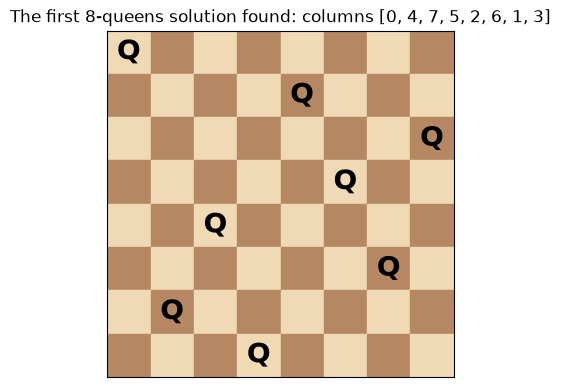

In [7]:
_, _, sols = n_queens(8, collect=True)
sol = sols[0]
fig, ax = plt.subplots(figsize=(4.5, 4.5))
for r in range(8):
    for c in range(8):
        ax.add_patch(plt.Rectangle((c, 7 - r), 1, 1, color="#f0d9b5" if (r + c) % 2 == 0 else "#b58863"))
for r, c in enumerate(sol):
    ax.text(c + 0.5, 7 - r + 0.5, "Q", ha="center", va="center", fontsize=20, color="black", fontweight="bold")
ax.set_xlim(0, 8); ax.set_ylim(0, 8); ax.set_aspect("equal"); ax.set_xticks([]); ax.set_yticks([])
ax.set_title(f"The first 8-queens solution found: columns {sol}")
plt.show()

**What just happened?** The backtracking counts match the known sequence 1, 0, 0, 2, 10, 4, 40, 92, 352, 724 for n = 1..10 (and a brute force over all `n!` column permutations for n ≤ 8). For n = 10 it visits about 35,000 nodes, compared with 10! ≈ 3.6 million permutations or 10¹⁰ unrestricted placements. The board shows the first solution found, `[0, 4, 7, 5, 2, 6, 1, 3]` (the queen in row `r` is in column `sol[r]`).

**Complexity:** the worst case is bounded by O(n!) leaves; pruning makes the real tree far smaller, but the growth is still exponential. O(n) space.

Let us draw the actual state-space tree for 4-queens, including the pruned branches. Each node is a partial placement; red nodes were attempted and immediately rejected by the attack check, so nothing below them is explored.

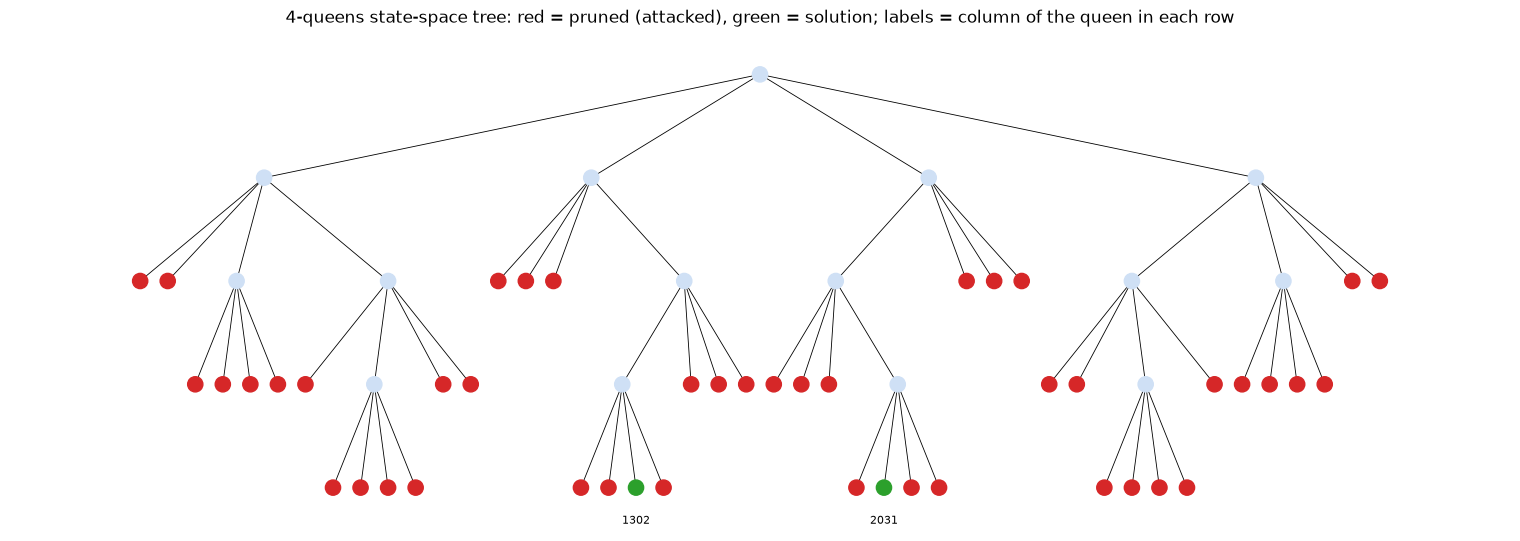

pruned           44
valid partial    15
solutions         2
Name: count, dtype: int64


In [8]:
def queens_tree(n):
    G, pos, colour, labels = nx.DiGraph(), {}, {}, {}
    next_x = itertools.count()
    def build(placement, depth):
        node = len(colour)
        G.add_node(node)
        labels[node] = "".join(str(c) for c in placement) if placement else "root"
        r = len(placement)
        ok = all(placement[i] != placement[j] and abs(placement[i] - placement[j]) != j - i
                 for i in range(r) for j in range(i + 1, r))
        colour[node] = "tab:red" if not ok else ("tab:green" if r == n else "#cfe0f5")
        kids = []
        if ok and r < n:
            for c in range(n):
                kids.append(build(placement + [c], depth + 1))
        for k in kids:
            G.add_edge(node, k)
        pos[node] = (next(next_x), -depth) if not kids else ((pos[kids[0]][0] + pos[kids[-1]][0]) / 2, -depth)
        return node
    build([], 0)
    return G, pos, colour, labels


G4, pos4, col4, lab4 = queens_tree(4)
plt.figure(figsize=(15, 5))
nx.draw(G4, pos4, node_color=[col4[v] for v in G4], node_size=120, arrows=False, width=0.6)
for v in G4:
    if col4[v] == "tab:green":
        x, y = pos4[v]
        plt.text(x, y - 0.35, lab4[v], ha="center", fontsize=8)
plt.title("4-queens state-space tree: red = pruned (attacked), green = solution; "
          "labels = column of the queen in each row")
plt.show()
counts = pd.Series([col4[v] for v in G4]).value_counts()
print(counts.rename({"tab:red": "pruned", "tab:green": "solutions", "#cfe0f5": "valid partial"}))

**What just happened?** Only a handful of blue (valid partial) nodes are ever expanded; every red node is a placement rejected on the spot, and its whole subtree is never generated. The two green leaves are the two 4-queens solutions, `1302` and `2031`.

## 7. Sudoku

> 💡 **In plain English:** fill a Sudoku by trying digits in empty cells, undoing them when they clash, and filling the most constrained cell first.

Fill a 9 × 9 grid so that every row, column and 3 × 3 box contains the digits 1-9 exactly once.

- **State:** the partially filled grid, plus a set of used digits per row, column and box (O(1) checks).
- **Choice:** a digit for one empty cell.
- **Constraint (pruning):** the digit is not already in that row, column or box.
- **Variable ordering:** naive = the first empty cell in reading order; **MRV (minimum remaining values)** = the empty cell with the **fewest** legal digits. MRV finds dead ends early (a cell with 0 candidates fails immediately) and makes forced moves (1 candidate) first.

We solve the example puzzle from Wikipedia's Sudoku article and a much harder puzzle published by Arto Inkala (2012), and count the nodes (digit placements tried) with both orderings.

In [9]:
def parse(puzzle):
    digits = [0 if ch in ".0" else int(ch) for ch in puzzle if ch in ".0123456789"]
    return [digits[r * 9:(r + 1) * 9] for r in range(9)]


def solve_sudoku(grid, mrv=True):
    g = [row[:] for row in grid]                                   # do not modify the input
    rows = [set() for _ in range(9)]; cols = [set() for _ in range(9)]; boxes = [set() for _ in range(9)]
    for r in range(9):
        for c in range(9):
            if g[r][c]:
                d = g[r][c]; rows[r].add(d); cols[c].add(d); boxes[r // 3 * 3 + c // 3].add(d)
    nodes = 0
    def candidates(r, c):
        used = rows[r] | cols[c] | boxes[r // 3 * 3 + c // 3]
        return [d for d in range(1, 10) if d not in used]
    def pick_cell():
        best = None
        for r in range(9):
            for c in range(9):
                if g[r][c] == 0:
                    if not mrv:
                        return r, c, candidates(r, c)                # naive: first empty cell
                    cs = candidates(r, c)
                    if best is None or len(cs) < len(best[2]):
                        best = (r, c, cs)
                        if len(cs) <= 1:
                            return best                              # cannot do better than 0 or 1
        return best
    def bt():
        nonlocal nodes
        cell = pick_cell()
        if cell is None:
            return True                                              # no empty cell left: solved
        r, c, cs = cell
        b = r // 3 * 3 + c // 3
        for d in cs:
            nodes += 1
            g[r][c] = d; rows[r].add(d); cols[c].add(d); boxes[b].add(d)          # choose
            if bt():                                                              # explore
                return True
            g[r][c] = 0; rows[r].remove(d); cols[c].remove(d); boxes[b].remove(d)  # un-choose
        return False
    solved = bt()
    return (g if solved else None), nodes


def is_valid_solution(sol, puzzle):
    full = set(range(1, 10))
    ok_rows = all(set(row) == full for row in sol)
    ok_cols = all({sol[r][c] for r in range(9)} == full for c in range(9))
    ok_boxes = all({sol[r][c] for r in range(br, br + 3) for c in range(bc, bc + 3)} == full
                   for br in (0, 3, 6) for bc in (0, 3, 6))
    keeps_givens = all(puzzle[r][c] in (0, sol[r][c]) for r in range(9) for c in range(9))
    return ok_rows and ok_cols and ok_boxes and keeps_givens


def show(grid):
    for r in range(9):
        if r in (3, 6): print("------+-------+------")
        print(" ".join((str(grid[r][c]) if grid[r][c] else ".") + (" |" if c in (2, 5) else "") for c in range(9)))


puzzles = {
    "Wikipedia example": "53..7.... 6..195... .98....6. 8...6...3 4..8.3..1 7...2...6 .6....28. ...419..5 ....8..79",
    "Inkala (very hard)": "8........ ..36..... .7..9.2.. .5...7... ....457.. ...1...3. ..1....68 ..85...1. .9....4..",
}
rows = []
for name, text in puzzles.items():
    p = parse(text)
    for mrv in (False, True):
        t0 = time.perf_counter()
        sol, nodes = solve_sudoku(p, mrv=mrv)
        rows.append({"puzzle": name, "ordering": "MRV" if mrv else "naive", "nodes": nodes,
                     "time (s)": round(time.perf_counter() - t0, 3)})
        assert sol is not None and is_valid_solution(sol, p)
print(pd.DataFrame(rows).to_string(index=False))
print("\nWikipedia puzzle:")
show(parse(puzzles["Wikipedia example"]))
print("\nsolution:")
show(solve_sudoku(parse(puzzles["Wikipedia example"]))[0])

            puzzle ordering  nodes  time (s)
 Wikipedia example    naive   4208     0.109
 Wikipedia example      MRV     51     0.008
Inkala (very hard)    naive  49558     1.190
Inkala (very hard)      MRV  13810     1.061

Wikipedia puzzle:
5 3 . | . 7 . | . . .
6 . . | 1 9 5 | . . .
. 9 8 | . . . | . 6 .
------+-------+------
8 . . | . 6 . | . . 3
4 . . | 8 . 3 | . . 1
7 . . | . 2 . | . . 6
------+-------+------
. 6 . | . . . | 2 8 .
. . . | 4 1 9 | . . 5
. . . | . 8 . | . 7 9

solution:
5 3 4 | 6 7 8 | 9 1 2
6 7 2 | 1 9 5 | 3 4 8
1 9 8 | 3 4 2 | 5 6 7
------+-------+------
8 5 9 | 7 6 1 | 4 2 3
4 2 6 | 8 5 3 | 7 9 1
7 1 3 | 9 2 4 | 8 5 6
------+-------+------
9 6 1 | 5 3 7 | 2 8 4
2 8 7 | 4 1 9 | 6 3 5
3 4 5 | 2 8 6 | 1 7 9


**What just happened?** Both orderings solve both puzzles, and every solution passes an independent validity check (each row, column and box is exactly {1..9} and the givens are kept). MRV cuts the number of nodes dramatically: on the easy puzzle almost every MRV move is forced, and on the hard one the reduction is still large (exact counts in the table). Choosing *which variable to assign next* is as important as pruning.

A Sudoku is a **constraint satisfaction problem** (CSP); section 15 links to the full CSP treatment.

## 8. Grids: rat in a maze and word search

> 💡 **In plain English:** find paths through a maze or a word in a letter grid, marking cells as used on the way in and freeing them on the way back.

### 8a. Rat in a maze (all paths)

A rat starts at the top-left cell of an `n × n` maze (`1` = open, `0` = wall) and must reach the bottom-right. It may move **D**own, **L**eft, **R**ight or **U**p, and may not visit a cell twice on one path. List every path. The key backtracking step is marking a cell as visited when entering it and **un-marking it when leaving**, so other paths may use it.

In [10]:
def rat_in_maze(maze):
    n = len(maze)
    paths, visited, moves = [], set(), []
    steps = [("D", 1, 0), ("L", 0, -1), ("R", 0, 1), ("U", -1, 0)]       # lexicographic order
    def bt(r, c):
        if (r, c) == (n - 1, n - 1):
            paths.append("".join(moves)); return
        for name, dr, dc in steps:
            nr, nc = r + dr, c + dc
            if 0 <= nr < n and 0 <= nc < n and maze[nr][nc] == 1 and (nr, nc) not in visited:
                visited.add((nr, nc)); moves.append(name)                 # choose
                bt(nr, nc)                                                # explore
                visited.remove((nr, nc)); moves.pop()                     # un-choose
    if maze[0][0] == 1 and maze[n - 1][n - 1] == 1:
        visited.add((0, 0))
        bt(0, 0)
    return paths


def maze_paths_networkx(maze):
    # Independent check: count simple paths in the grid graph with networkx
    n = len(maze)
    G = nx.grid_2d_graph(n, n)
    G.remove_nodes_from([(r, c) for r in range(n) for c in range(n) if maze[r][c] == 0])
    if (0, 0) not in G or (n - 1, n - 1) not in G:
        return 0
    if (0, 0) == (n - 1, n - 1):
        return 1
    return sum(1 for _ in nx.all_simple_paths(G, (0, 0), (n - 1, n - 1)))


maze = [[1, 0, 0, 0],
        [1, 1, 0, 1],
        [1, 1, 0, 0],
        [0, 1, 1, 1]]
print("paths:", rat_in_maze(maze))
for _ in range(200):
    n = random.randint(1, 4)
    mz = [[1 if random.random() < 0.75 else 0 for _ in range(n)] for _ in range(n)]
    assert len(rat_in_maze(mz)) == maze_paths_networkx(mz)
print("rat_in_maze path counts match networkx.all_simple_paths on 200 random mazes")

paths: ['DDRDRR', 'DRDDRR']
rat_in_maze path counts match networkx.all_simple_paths on 200 random mazes


**What just happened?** The example maze has two paths, `DDRDRR` and `DRDDRR`; the counts agree with networkx's independent simple-path enumeration on 200 random mazes.

### 8b. Word search

Does a word appear in a letter grid as a path of horizontally/vertically adjacent cells, using each cell at most once? Backtracking: start from every cell matching the first letter, extend to neighbours matching the next letter, and **prune** as soon as a letter does not match.

In [11]:
def word_search(board, word):
    R, C = len(board), len(board[0])
    used = set()
    def bt(r, c, k):                                   # board[r][c] should match word[k]
        if not (0 <= r < R and 0 <= c < C) or (r, c) in used or board[r][c] != word[k]:
            return False                               # pruning: off-board, reused, or wrong letter
        if k == len(word) - 1:
            return True
        used.add((r, c))                               # choose
        found = any(bt(r + dr, c + dc, k + 1) for dr, dc in ((1, 0), (-1, 0), (0, 1), (0, -1)))
        used.remove((r, c))                            # un-choose
        return found
    return any(bt(r, c, 0) for r in range(R) for c in range(C)) if word else True


def word_search_brute(board, word):
    # Try every sequence of distinct cells of the right length
    R, C = len(board), len(board[0])
    cells = [(r, c) for r in range(R) for c in range(C)]
    for seq in itertools.permutations(cells, len(word)):
        if all(board[r][c] == ch for (r, c), ch in zip(seq, word)) and \
           all(abs(a[0] - b[0]) + abs(a[1] - b[1]) == 1 for a, b in zip(seq, seq[1:])):
            return True
    return len(word) == 0


board = [list("ABCE"), list("SFCS"), list("ADEE")]
for w in ["ABCCED", "SEE", "ABCB"]:
    print(w, word_search(board, w))
for _ in range(300):
    R, C = random.randint(1, 3), random.randint(1, 3)
    bd = [[random.choice("ab") for _ in range(C)] for _ in range(R)]
    w = "".join(random.choice("ab") for _ in range(random.randint(1, 4)))
    assert word_search(bd, w) == word_search_brute(bd, w)
print("word_search matches brute force on 300 random boards")

ABCCED True
SEE True
ABCB False


word_search matches brute force on 300 random boards


**What just happened?** "ABCCED" and "SEE" are found; "ABCB" is not, because it would need to reuse the `B` cell. Random small boards agree with a brute force over all sequences of distinct cells.

**Complexity:** O(R·C · 3^(L−1)) for a word of length `L` (after the first step each cell has at most 3 unvisited neighbours), O(L) space.

## 9. Graph m-colouring

> 💡 **In plain English:** colour a map or graph so that no two neighbours share a colour, using at most m colours.

Colour the vertices of a graph with at most `m` colours so that adjacent vertices differ (think: schedule exams so that no student has two exams in the same slot; colours are time slots). The smallest such `m` is the **chromatic number** χ(G). Deciding whether `m = 3` colours suffice is NP-complete.

Backtracking: colour vertices one by one; for each, try colours `0..m−1` that no already-coloured neighbour uses; backtrack if none fits.

m_colouring matches brute force on 200 random graphs (m = 1..3)
Petersen graph: 2-colourable? False | chromatic number: 3


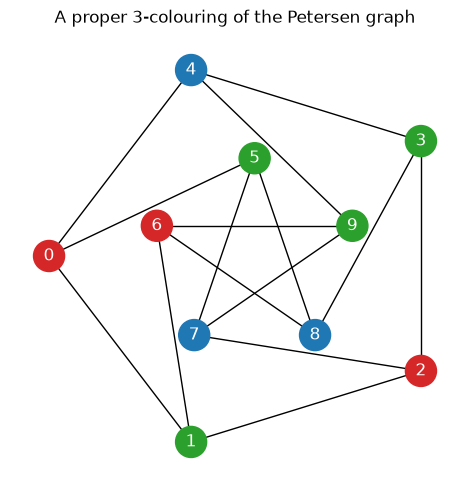

In [12]:
def m_colouring(G, m):
    order = list(G.nodes)
    colour = {}
    def bt(i):
        if i == len(order):
            return True
        v = order[i]
        for c in range(m):
            if all(colour.get(u) != c for u in G[v]):    # pruning: neighbour already has c
                colour[v] = c                           # choose
                if bt(i + 1):                           # explore
                    return True
                del colour[v]                           # un-choose
        return False
    return dict(colour) if bt(0) else None


def colourable_brute(G, m):
    nodes = list(G.nodes)
    idx = {v: i for i, v in enumerate(nodes)}
    return any(all(assign[idx[u]] != assign[idx[v]] for u, v in G.edges)
               for assign in itertools.product(range(m), repeat=len(nodes)))


def chromatic_number(G):
    for m in range(1, G.number_of_nodes() + 1):
        if m_colouring(G, m) is not None:
            return m
    return 0                                              # empty graph


for _ in range(200):
    n = random.randint(1, 7)
    G = nx.gnp_random_graph(n, random.random(), seed=random.randint(0, 10 ** 6))
    for m in range(1, 4):
        col = m_colouring(G, m)
        assert (col is not None) == colourable_brute(G, m)
        if col:
            assert all(col[u] != col[v] for u, v in G.edges) and max(col.values(), default=0) < m
print("m_colouring matches brute force on 200 random graphs (m = 1..3)")

P = nx.petersen_graph()
print("Petersen graph: 2-colourable?", m_colouring(P, 2) is not None, "| chromatic number:", chromatic_number(P))
col = m_colouring(P, 3)
pos = nx.shell_layout(P, nlist=[range(5, 10), range(5)])
plt.figure(figsize=(4.5, 4.5))
nx.draw(P, pos, node_color=[["tab:red", "tab:green", "tab:blue"][col[v]] for v in P],
        with_labels=True, font_color="white", node_size=500)
plt.title("A proper 3-colouring of the Petersen graph")
plt.show()

**What just happened?** Backtracking agrees with brute force on 200 random graphs. The Petersen graph cannot be 2-coloured (it contains 5-cycles, and an odd cycle needs 3 colours) but can be 3-coloured, so χ = 3. **Complexity:** O(mⁿ) worst case, O(n) space; pruning and good vertex orderings (e.g. highest degree first, the same idea as MRV) make it practical for moderate graphs.

## 10. Hamiltonian paths

> 💡 **In plain English:** find a route that visits every point exactly once, growing the route one step at a time.

A **Hamiltonian path** visits every vertex of a graph exactly once (a **Hamiltonian cycle** also returns to the start). Unlike Euler paths (every *edge* once, decidable in linear time), deciding whether a Hamiltonian path exists is NP-complete. Backtracking extends a path one unvisited neighbour at a time.

hamiltonian_path matches brute force on 200 random graphs
Hamiltonian path: [0, 7, 8, 2, 3, 4, 5, 1, 6]


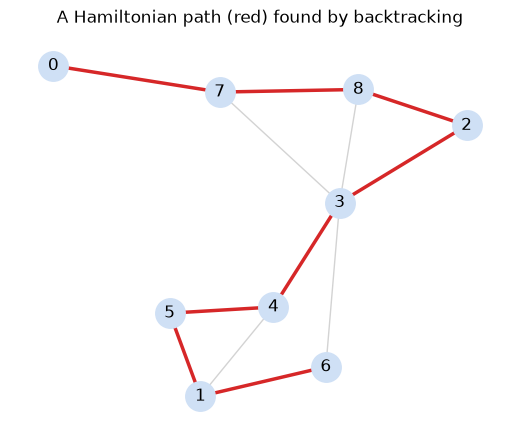

In [13]:
def hamiltonian_path(G):
    n = G.number_of_nodes()
    path, on_path = [], set()
    def bt(v):
        path.append(v); on_path.add(v)                  # choose
        if len(path) == n:
            return True
        for u in G[v]:
            if u not in on_path and bt(u):              # explore unvisited neighbours only
                return True
        path.pop(); on_path.remove(v)                   # un-choose
        return False
    for start in G.nodes:                               # the path may start anywhere
        if bt(start):
            return path
    return None if n else []


def hamiltonian_brute(G):
    return any(all(G.has_edge(p[i], p[i + 1]) for i in range(len(p) - 1))
               for p in itertools.permutations(G.nodes))


for _ in range(200):
    n = random.randint(1, 7)
    G = nx.gnp_random_graph(n, random.uniform(0.2, 0.8), seed=random.randint(0, 10 ** 6))
    hp = hamiltonian_path(G)
    assert (hp is not None) == hamiltonian_brute(G)
    if hp:
        assert sorted(hp) == sorted(G.nodes) and all(G.has_edge(a, b) for a, b in zip(hp, hp[1:]))
print("hamiltonian_path matches brute force on 200 random graphs")

G = nx.gnp_random_graph(9, 0.35, seed=11)
hp = hamiltonian_path(G)
print("Hamiltonian path:", hp)
pos = nx.spring_layout(G, seed=2)
plt.figure(figsize=(5, 4))
nx.draw(G, pos, with_labels=True, node_color="#cfe0f5", edge_color="lightgray", node_size=450)
if hp:
    nx.draw_networkx_edges(G, pos, edgelist=list(zip(hp, hp[1:])), edge_color="tab:red", width=2.5)
plt.title("A Hamiltonian path (red) found by backtracking")
plt.show()

**What just happened?** The backtracking search agrees with a brute force over all `n!` vertex orders, and the drawing highlights the path it found. **Complexity:** O(n!) in the worst case, O(n) space. (A bitmask DP like Held-Karp in notebook 09 solves it in Θ(2ⁿ·n²), which is better for n up to about 20.)

## 11. Generating balanced parentheses

> 💡 **In plain English:** build every correctly matched string of brackets, only adding a bracket when it can still lead to a valid string.

List all strings of `n` pairs of correctly matched parentheses. `n = 3` → `((()))`, `(()())`, `(())()`, `()(())`, `()()()`.

Instead of generating all `2^(2n)` strings and filtering, prune while building:
- add `(` only if fewer than `n` have been opened;
- add `)` only if it closes something (`close < open`).

Every leaf is then valid. The count is the **Catalan number** `C_n = (2n choose n) / (n + 1)`: 1, 1, 2, 5, 14, 42, 132, …

In [14]:
def balanced_parens(n, counter=None):
    out, current = [], []
    def bt(opened, closed):
        if counter is not None: counter[0] += 1
        if len(current) == 2 * n:
            out.append("".join(current)); return
        if opened < n:
            current.append("("); bt(opened + 1, closed); current.pop()
        if closed < opened:
            current.append(")"); bt(opened, closed + 1); current.pop()
    bt(0, 0)
    return out


def is_balanced(s):
    depth = 0
    for ch in s:
        depth += 1 if ch == "(" else -1
        if depth < 0:
            return False
    return depth == 0


print(balanced_parens(3))
rows = []
for n in range(0, 9):
    cnt = [0]
    got = balanced_parens(n, cnt)
    catalan = math.comb(2 * n, n) // (n + 1)
    assert len(got) == catalan and all(is_balanced(s) for s in got) and len(set(got)) == len(got)
    if n <= 6:
        brute = sorted("".join(p) for p in itertools.product("()", repeat=2 * n) if is_balanced("".join(p)))
        assert sorted(got) == brute
    rows.append({"n": n, "Catalan C_n": catalan, "nodes visited (pruned)": cnt[0],
                 "nodes in full binary tree": 2 ** (2 * n + 1) - 1})
print(pd.DataFrame(rows).to_string(index=False))

['((()))', '(()())', '(())()', '()(())', '()()()']
 n  Catalan C_n  nodes visited (pruned)  nodes in full binary tree
 0            1                       1                          1
 1            1                       3                          7
 2            2                       8                         31
 3            5                      22                        127
 4           14                      64                        511
 5           42                     196                       2047
 6          132                     625                       8191
 7          429                    2055                      32767
 8         1430                    6917                     131071


**What just happened?** The counts are the Catalan numbers, every string is balanced, and for n ≤ 6 the result equals the filtered brute force. The node counts show the pruning: for n = 8 the pruned search visits 6,917 nodes, about 5% of the 131,071 nodes in the full binary tree of all 2¹⁶ strings.

## 12. Palindrome partitioning

> 💡 **In plain English:** cut a word into pieces that each read the same backwards and forwards, listing every way to do it.

Split a string into pieces that are all palindromes, and list every way. `"aab"` → `["a", "a", "b"]` and `["aa", "b"]`.

Backtracking: at position `start`, try every end `i` such that `s[start:i+1]` is a palindrome (pruning: non-palindromic prefixes are never extended), then recurse from `i + 1`. A DP table `pal[i][j]` (notebook 09) makes each palindrome check O(1): this is a nice example of **backtracking + DP together**.

In [15]:
def palindrome_partitions(s):
    n = len(s)
    pal = [[False] * n for _ in range(n)]                  # pal[i][j]: is s[i..j] a palindrome?
    for i in range(n - 1, -1, -1):
        for j in range(i, n):
            pal[i][j] = s[i] == s[j] and (j - i < 2 or pal[i + 1][j - 1])
    out, current = [], []
    def bt(start):
        if start == n:
            out.append(current.copy()); return
        for end in range(start, n):
            if pal[start][end]:                            # pruning: only palindromic pieces
                current.append(s[start:end + 1])           # choose
                bt(end + 1)                                # explore
                current.pop()                              # un-choose
    bt(0)
    return out


def palindrome_partitions_brute(s):
    # Every subset of the n-1 cut positions gives one partition; keep the all-palindrome ones
    res = []
    for mask in range(1 << max(len(s) - 1, 0)):
        parts, last = [], 0
        for i in range(1, len(s)):
            if mask >> (i - 1) & 1:
                parts.append(s[last:i]); last = i
        parts.append(s[last:])
        if all(p == p[::-1] for p in parts):
            res.append(parts)
    return sorted(res) if s else [[]]


print(palindrome_partitions("aab"))
print(len(palindrome_partitions("racecar")), "partitions of 'racecar'")
for _ in range(300):
    s = "".join(random.choice("ab") for _ in range(random.randint(0, 10)))
    assert sorted(palindrome_partitions(s)) == palindrome_partitions_brute(s)
print("palindrome_partitions matches brute force on 300 random strings")

[['a', 'a', 'b'], ['aa', 'b']]
4 partitions of 'racecar'


palindrome_partitions matches brute force on 300 random strings


**Complexity:** O(n · 2ⁿ) in the worst case (a string of one repeated letter: every one of the 2ⁿ⁻¹ cut patterns is valid), O(n²) for the palindrome table.

## 13. Measuring how much pruning saves

> 💡 **In plain English:** we count how many steps the search takes with and without pruning, and the difference is huge.

Let us compare three ways to solve N-Queens, counting the nodes of the state-space tree each one visits:

1. **No pruning:** put one queen per row in any column (n choices each) and test only complete boards. Tree size `1 + n + n² + … + nⁿ`.
2. **Column pruning only:** never reuse a column (permutation tree). Tree size `Σ n!/(n−k)!`.
3. **Full pruning:** reject any square attacked along a column **or a diagonal** (section 6).

We run (1) for small `n` and compute its size by formula for larger `n`, and we also measure **subset sum** with and without a bound-pruning rule.

     no pruning  column pruning  column + diagonal pruning reduction vs no pruning
n                                                                                 
4           341              65                         17                     20x
5          3906             326                         54                     72x
6         55987            1957                        153                    366x
7        960800           13700                        552                  1,741x
8      19173961          109601                       2057                  9,321x
9     435848050          986410                       8394                 51,924x
10  11111111111         9864101                      35539                312,646x


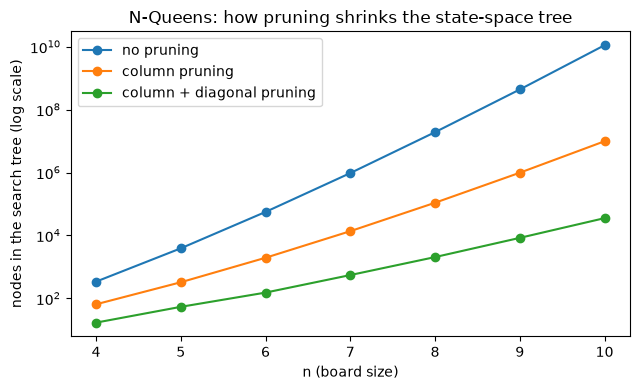

In [16]:
def queens_no_pruning(n):
    nodes = solutions = 0
    placement = []
    def bt():
        nonlocal nodes, solutions
        nodes += 1
        if len(placement) == n:
            p = placement
            if all(p[i] != p[j] and abs(p[i] - p[j]) != j - i for i in range(n) for j in range(i + 1, n)):
                solutions += 1                               # check only at the very end
            return
        for c in range(n):
            placement.append(c); bt(); placement.pop()
    bt()
    return solutions, nodes


rows = []
for n in range(4, 11):
    no_prune_nodes = sum(n ** k for k in range(n + 1))
    if n <= 6:
        sols, measured = queens_no_pruning(n)
        assert measured == no_prune_nodes and sols == known[n]
    col_only = sum(math.perm(n, k) for k in range(n + 1))
    full = n_queens(n)[1]
    rows.append({"n": n, "no pruning": no_prune_nodes, "column pruning": col_only,
                 "column + diagonal pruning": full,
                 "reduction vs no pruning": f"{no_prune_nodes / full:,.0f}x"})
df = pd.DataFrame(rows).set_index("n")
print(df.to_string())

fig, ax = plt.subplots(figsize=(6.5, 4))
for col in ["no pruning", "column pruning", "column + diagonal pruning"]:
    ax.plot(df.index, df[col], marker="o", label=col)
ax.set_yscale("log"); ax.set_xlabel("n (board size)"); ax.set_ylabel("nodes in the search tree (log scale)")
ax.set_title("N-Queens: how pruning shrinks the state-space tree"); ax.legend()
plt.tight_layout(); plt.show()

In [17]:
def subset_sum_bt(nums, target, prune=True):
    # Find one subset of positive nums with the given sum; count visited nodes
    nums = sorted(nums, reverse=True)
    suffix = [0] * (len(nums) + 1)                          # suffix[i] = sum(nums[i:])
    for i in range(len(nums) - 1, -1, -1):
        suffix[i] = suffix[i + 1] + nums[i]
    nodes = 0
    def bt(i, total):
        nonlocal nodes
        nodes += 1
        if total == target:
            return True
        if i == len(nums):
            return False
        if prune and (total > target or total + suffix[i] < target):
            return False                                    # bound pruning: overshot, or cannot reach
        return bt(i + 1, total + nums[i]) or bt(i + 1, total)
    found = bt(0, 0)
    return found, nodes


rows = []
for n in [10, 14, 18]:
    nums = [random.randint(1, 1000) for _ in range(n)]
    target = sum(nums) // 2 + 1                             # a hard-ish target
    f1, n1 = subset_sum_bt(nums, target, prune=False)
    f2, n2 = subset_sum_bt(nums, target, prune=True)
    exact = any(sum(c) == target for r in range(n + 1) for c in itertools.combinations(nums, r)) if n <= 14 else f1
    assert f1 == f2 == exact
    rows.append({"n": n, "found?": f1, "nodes without pruning": n1, "nodes with bound pruning": n2})
print(pd.DataFrame(rows).to_string(index=False))

 n  found?  nodes without pruning  nodes with bound pruning
10   False                   2047                       351
14    True                  14496                      1110
18    True                  32169                       371


**What just happened?** For N-Queens the "no pruning" tree for n = 10 has over 11 billion nodes, the permutation tree about 9.9 million, and full pruning visits about 35,000: a reduction by a factor of hundreds of thousands. (We only *ran* the no-pruning version for n ≤ 6, where the formula and the measured count agree; beyond that it would take hours.) For subset sum, the two bound rules (stop if we already overshot; stop if even taking every remaining number cannot reach the target) also cut the node count substantially (exact numbers in the table). Pruning does not change the worst-case exponential class, but it decides whether a problem is solvable in practice.

## 14. Backtracking vs. DP vs. brute force

> 💡 **In plain English:** a guide to choosing between trying everything, backtracking and dynamic programming.

| | Brute force (generate and test) | Backtracking | Dynamic programming |
|---|---|---|---|
| Idea | enumerate every complete candidate, then test it | build candidates incrementally, abandon partial ones that fail | solve each distinct subproblem once and reuse it |
| Prunes partial solutions? | no | **yes** (constraints, bounds, symmetry) | not needed: it merges equal subproblems |
| Typical time | size of the full candidate space (`2ⁿ`, `n!`, `kⁿ`) | worst case the same, usually far less | (number of states) × (work per state), often polynomial or pseudo-polynomial |
| Memory | O(1) beyond one candidate | O(depth) | O(number of states) (often reducible) |
| Finds | all / best solutions | **all** solutions, or the first, or the best with branch and bound | usually the **optimal value / count** (plus one optimal solution by reconstruction) |
| Best when | the space is tiny, or as a correctness checker | you must **list** solutions, or constraints prune heavily, or there is no repeated substructure | subproblems **overlap** and you need an optimum or a count |
| Examples | testing all 2ⁿ subsets for subset sum | N-Queens, Sudoku, permutations, m-colouring, word search | knapsack, LCS, edit distance, counting paths |

**How to choose:**
1. Need to **list every** solution (all permutations, all partitions)? The output itself is exponential, so backtracking is the natural tool.
2. Need only the **number** of solutions or the **best value**, and the future only depends on a small "state" (an index, a remaining capacity, a subset mask)? Look for **DP**: e.g. counting balanced parentheses (Catalan recurrence) or subset sum with a small target.
3. Strong **constraints** that kill most partial candidates early? Backtracking with pruning and good ordering (MRV), i.e. CSP solving.
4. Tiny input, or writing a **test oracle**? Brute force, exactly as we used it throughout this notebook.

> ⚠️ **Common mistake:** forgetting the **un-choose** step (or undoing it incompletely, e.g. removing a queen's column but not her diagonals). The search then silently skips valid branches and reports too few solutions. Testing against brute force on small inputs catches this immediately.

## 15. 🔗 How this connects to AI

> 💡 **In plain English:** backtracking is the engine inside AI puzzle solvers, logic programming, chess engines and LLM reasoning that explores and abandons ideas.

- **Constraint satisfaction problems (CSPs).** Sudoku, N-Queens and graph colouring are textbook CSPs: variables, domains and constraints. AI CSP solvers are backtracking plus three upgrades you have already met informally: **variable ordering** (MRV, degree heuristic), **value ordering** (least-constraining value), and **inference** (forward checking and arc consistency, AC-3, which delete impossible values from neighbours' domains before branching). See [`06_constraint_satisfaction.ipynb`](../classical_ai/06_constraint_satisfaction.ipynb) in the classical AI track of this module set.
- **SAT solvers.** The DPLL algorithm is backtracking over Boolean variables with unit propagation; modern CDCL solvers add clause learning and non-chronological backtracking. They verify hardware, schedule, and solve planning problems.
- **Logic programming.** Prolog answers queries by depth-first backtracking search over rules.
- **Game playing.** Minimax search explores a game tree depth-first with the same choose/explore/un-choose pattern (make a move, recurse, undo the move), and **alpha-beta pruning** is bound pruning.
- **Combinatorial optimisation.** Branch and bound (backtracking + bound pruning) is the core of mixed-integer programming solvers used for scheduling, routing and supply chains.
- **LLM reasoning.** Tree-of-Thoughts style prompting (2023) and agentic planners explore several reasoning steps, evaluate partial solutions, and backtrack from dead ends: a learned version of the state-space search in this notebook. See [`08_LLM/18_reasoning_models.ipynb`](../../08_LLM/18_reasoning_models.ipynb).

## 16. Recap

> 💡 **In plain English:** the key ideas in a few bullets, then practice problems to check you really understood them.

- Backtracking = depth-first search of the **state-space tree** of partial solutions, using **choose → explore → un-choose** on one shared state.
- **Pruning** (feasibility, bounds, symmetry/duplicates) and **ordering** (MRV) shrink the tree by orders of magnitude, but the worst case stays exponential.
- Classic templates: subsets (2ⁿ), permutations (n!, skip equal values whose previous copy is unused), combinations / combination sum (sorted candidates + `break`), N-Queens (column and two diagonal sets: 1, 0, 0, 2, 10, 4, 40, 92, 352, 724 for n = 1..10), Sudoku (row/column/box sets + MRV), grid paths and word search (mark/unmark visited), m-colouring, Hamiltonian paths, balanced parentheses (Catalan numbers), palindrome partitioning (with a DP palindrome table).
- Use **brute force** as a test oracle, **backtracking** to list solutions or when constraints prune hard, and **DP** when subproblems overlap and you need a count or an optimum.
- Backtracking is the engine behind CSP and SAT solvers, Prolog, game-tree search and branch-and-bound.

## Practice problems

**1. (Easy, conceptual)** How many leaves does the state-space tree of permutations of 5 distinct items have, and how many nodes in total?

<details><summary>Show solution</summary>

Leaves: 5! = 120. Nodes: Σ_(k=0..5) 5!/(5−k)! = 1 + 5 + 20 + 60 + 120 + 120 = 326.
</details>

**2. (Easy, coding)** Generate all **subsets of a list with duplicates** without repeated subsets (e.g. `[1, 2, 2]` → 6 subsets).

<details><summary>Show solution</summary>

Sort, and in the loop-from-start style skip `items[i]` when `i > start and items[i] == items[i−1]`.

```python
def subsets_with_dup(items):
    items, out, cur = sorted(items), [], []
    def bt(start):
        out.append(cur.copy())
        for i in range(start, len(items)):
            if i > start and items[i] == items[i - 1]:
                continue                       # same value already tried at this depth
            cur.append(items[i]); bt(i + 1); cur.pop()
    bt(0)
    return out
assert sorted(subsets_with_dup([1, 2, 2])) == [[], [1], [1, 2], [1, 2, 2], [2], [2, 2]]
```
</details>

**3. (Medium, conceptual)** In N-Queens, why are `row − col` and `row + col` enough to identify the two diagonals of a square?

<details><summary>Show solution</summary>

Moving one step along a "↘" diagonal adds 1 to both row and column, so `row − col` is constant on it, and different ↘ diagonals have different values. Moving along a "↙" diagonal adds 1 to the row and subtracts 1 from the column, so `row + col` is constant. Hence two squares share a diagonal exactly when they share one of these values.
</details>

**4. (Medium, coding)** **Combination sum II:** each candidate may be used **at most once** and the candidates may contain duplicates; list the unique combinations summing to the target. `[10, 1, 2, 7, 6, 1, 5]`, target 8 → `[1,1,6], [1,2,5], [1,7], [2,6]`.

<details><summary>Show solution</summary>

```python
def combination_sum2(cands, target):
    cands, out, cur = sorted(cands), [], []
    def bt(start, rem):
        if rem == 0:
            out.append(cur.copy()); return
        for i in range(start, len(cands)):
            if i > start and cands[i] == cands[i - 1]:
                continue                       # skip duplicate values at the same depth
            if cands[i] > rem:
                break                          # sorted: nothing later fits either
            cur.append(cands[i]); bt(i + 1, rem - cands[i]); cur.pop()   # i + 1: use once
    bt(0, target)
    return out
assert combination_sum2([10, 1, 2, 7, 6, 1, 5], 8) == [[1, 1, 6], [1, 2, 5], [1, 7], [2, 6]]
```
</details>

**5. (Medium, conceptual)** You must count (not list) the subsets of `n = 60` numbers that sum to `T = 500`. Backtracking or DP? Why?

<details><summary>Show solution</summary>

DP. There can be astronomically many subsets (up to 2⁶⁰), so listing or even visiting them is hopeless, but the subproblem "how many subsets of the first `i` numbers sum to `t`" has only 61 × 501 states: `ways[t] += ways[t − x]` (downward loop) counts them in Θ(n·T).
</details>

**6. (Hard, coding)** Count the **knight's tours** that start in the corner of a 5 × 5 board (a knight visits every square exactly once; the tour does not need to return). The answer is 304.

<details><summary>Show solution</summary>

```python
def knight_tours(n, start=(0, 0)):
    moves = [(1, 2), (2, 1), (2, -1), (1, -2), (-1, -2), (-2, -1), (-2, 1), (-1, 2)]
    seen = {start}
    def bt(r, c):
        if len(seen) == n * n:
            return 1
        total = 0
        for dr, dc in moves:
            nr, nc = r + dr, c + dc
            if 0 <= nr < n and 0 <= nc < n and (nr, nc) not in seen:
                seen.add((nr, nc)); total += bt(nr, nc); seen.remove((nr, nc))
        return total
    return bt(*start)
assert knight_tours(5) == 304
```
It is a Hamiltonian-path search on the knight's-move graph. For 8 × 8, plain backtracking is far too slow; Warnsdorff's heuristic (move to the square with the fewest onward moves, an MRV idea) finds a single tour almost instantly.
</details>

**7. (Hard, conceptual)** Explain why the MRV heuristic can reduce the Sudoku search tree even though it does not remove any solutions.

<details><summary>Show solution</summary>

The size of the tree depends on the branching factor at each level. Choosing a cell with 1 candidate adds no branching (a forced move), and choosing a cell with 0 candidates fails immediately, cutting the current branch at the top instead of after many more assignments. Picking a cell with many candidates early multiplies the work of every later failure. MRV changes the *order* of variables, not the set of solutions, so it is complete and correct, but it moves failures up the tree where they are cheap.
</details>

## Further reading

- Russell and Norvig, *Artificial Intelligence: A Modern Approach* (AIMA), 4th ed., ch. 6 "Constraint Satisfaction Problems" (backtracking search, MRV, forward checking, AC-3).
- Skiena, *The Algorithm Design Manual*, 3rd ed., ch. 9 "Combinatorial Search" (backtracking, pruning, Sudoku).
- Knuth, *The Art of Computer Programming*, Vol. 4B (2022), section 7.2.2 "Backtrack programming" (dancing links for exact cover).
- Jeff Erickson, *Algorithms* (free online), ch. 2 "Backtracking".
- GeeksforGeeks "Backtracking Algorithms" tutorial for more practice problems.

## Next notebook

Continue with [`11_advanced_tries_strings_and_range_queries.ipynb`](11_advanced_tries_strings_and_range_queries.ipynb). If you want to see backtracking grow into a full AI technique, also open [`06_constraint_satisfaction.ipynb`](../classical_ai/06_constraint_satisfaction.ipynb) in the classical AI track.